# Capstone Project for Strategic AI Deployment


In this walkthrough, students will develop an AI-driven solution strategy tailored to a specific business problem.

**Scenario:**
Your healthcare client is struggling to predict patient readmissions. Develop an AI solution to address this issue, and prepare a proposal highlighting the business value.

**Objective:**
- Define the problem and business goals.
- Select an AI architecture and justify their choice.
- Outline a data strategy, deployment plan, and risk mitigation strategies.
- Use Hospital Readmission data to create a working model that addresses the clients problem.




In [1]:
# Define the problem and business goals.
## Unplanned 30-day readmissions cost the client money and often signal care that could have been better. Care management has limited follow-up capacity and learns a patient was high-risk only after they return. The goal is to flag high-risk patients at discharge so that limited capacity goes where it matters most.

### Business goal: lower the 30-day readmission rate among flagged patients, measured against a historical baseline. The target is agreed with the client.
### Model goal: recall on readmitted patients, meaning the share of truly at-risk patients the model flags.

# Select an AI architecture and justify their choice.
# I’d choose Logistic Regression as the baseline and reference model. It is the most interpretable option, so case managers can see why a patient was flagged. It is also no worse than the alternatives on this data.

# Outline a data strategy, deployment plan, and risk mitigation strategies.
## Data strategy: drop Patient_ID, remove the impossible Age = 150 rows with the IQR rule, and decide how to handle the 43% of missing A1C_Result values (keep the rows and model missingness, rather than dropping them). Split into training and test sets with a stratified 90/10 split, and fit all scalers on the training data only.
## Deployment plan: first close the data gap (prior admissions, medication adherence, lab results, social factors). Then run a shadow pilot where the model flags patients without triggering any action. Only after the flags beat random selection on real outcomes should they inform human-reviewed outreach. Retrain quarterly and monitor for drift.
## Risk mitigation:
### Weak signal: do not deploy until holdout AUC is clearly above 0.5.
### Data loss from dropping rows: keep missing-A1C patients and check whether they differ from the rest.
### Clinical adoption: involve case managers in the pilot and use an interpretable model.
### Fairness: audit performance by age, gender and diagnosis before any rollout.
### Leakage: fit every transform on the training split only.


### Part 1: Load the 'hospital_readmissions_data.csv' dataset from the data directory into a Pandas DataFrame.

**Task 1:**
- Load and Preprocess the dataset.
- Perform EDA to understand patterns in the dataset
- Data Preprocessing
- Split the dataset into training and testing datasets

In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,precision_score,confusion_matrix,classification_report
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler

In [3]:
#IMPORTING THE DATA 
df=pd.read_csv('./data/hospital_readmissions_data.csv')
df.head()

,Patient_ID,Age,Gender,Admission_Type,Diagnosis,Num_Lab_Procedures,Num_Medications,Num_Outpatient_Visits,Num_Inpatient_Visits,Num_Emergency_Visits,Num_Diagnoses,A1C_Result,Readmitted
0,1,69,Other,Emergency,Heart Disease,33,2,4,1,1,5,NaN,Yes
1,2,32,Female,Urgent,Diabetes,81,10,4,4,1,6,NaN,No
2,3,78,Female,Urgent,Heart Disease,75,29,4,0,3,5,Normal,No
3,4,38,Male,Elective,Diabetes,77,11,2,3,4,9,NaN,Yes
4,5,41,Female,Urgent,Diabetes,50,25,3,4,1,3,NaN,Yes


In [4]:
df.describe()

,Patient_ID,Age,Num_Lab_Procedures,Num_Medications,Num_Outpatient_Visits,Num_Inpatient_Visits,Num_Emergency_Visits,Num_Diagnoses
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,51.665000,50.836000,15.661000,2.016000,2.019000,1.956000,5.011000
std,288.819436,21.989459,28.075137,8.230177,1.399894,1.416561,1.409983,2.664203
min,1.000000,18.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,250.750000,34.000000,27.000000,9.000000,1.000000,1.000000,1.000000,3.000000
50%,500.500000,50.500000,52.000000,16.000000,2.000000,2.000000,2.000000,5.000000
75%,750.250000,69.000000,75.000000,23.000000,3.000000,3.000000,3.000000,7.000000
max,1000.000000,150.000000,99.000000,35.000000,4.000000,4.000000,4.000000,9.000000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Patient_ID             1000 non-null   int64
 1   Age                    1000 non-null   int64
 2   Gender                 1000 non-null   str  
 3   Admission_Type         1000 non-null   str  
 4   Diagnosis              1000 non-null   str  
 5   Num_Lab_Procedures     1000 non-null   int64
 6   Num_Medications        1000 non-null   int64
 7   Num_Outpatient_Visits  1000 non-null   int64
 8   Num_Inpatient_Visits   1000 non-null   int64
 9   Num_Emergency_Visits   1000 non-null   int64
 10  Num_Diagnoses          1000 non-null   int64
 11  A1C_Result             566 non-null    str  
 12  Readmitted             1000 non-null   str  
dtypes: int64(8), str(5)
memory usage: 129.3 KB


In [6]:
df=df.drop(columns=['Patient_ID'])
df.columns

Index(['Age', 'Gender', 'Admission_Type', 'Diagnosis', 'Num_Lab_Procedures',
       'Num_Medications', 'Num_Outpatient_Visits', 'Num_Inpatient_Visits',
       'Num_Emergency_Visits', 'Num_Diagnoses', 'A1C_Result', 'Readmitted'],
      dtype='str')

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Load and drop the identifier
df = pd.read_csv('data/hospital_readmissions_data.csv')
df = df.drop(columns=['Patient_ID'])

# 2. Remove impossible Age values with the IQR rule
q1, q3 = df['Age'].quantile([0.25, 0.75])
iqr = q3 - q1
df = df[(df['Age'] >= q1 - 1.5 * iqr) & (df['Age'] <= q3 + 1.5 * iqr)].reset_index(drop=True)

# 3. Keep every row; treat a missing A1C test as its own category
df['A1C_Result'] = df['A1C_Result'].fillna('Not measured')

# 4. Separate features from the target, then one-hot encode the categories
y = (df['Readmitted'] == 'Yes').astype(int)
X = pd.get_dummies(df.drop(columns=['Readmitted']), drop_first=False).astype(float)

# 5. Split first, so the test set stays untouched by any later step
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=72, stratify=y
)

# 6. Scale numeric columns, fitting the scaler on the training set only
numeric_cols = ['Age', 'Num_Lab_Procedures', 'Num_Medications', 'Num_Outpatient_Visits',
                'Num_Inpatient_Visits', 'Num_Emergency_Visits', 'Num_Diagnoses']
scaler = StandardScaler()
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

print('X_train', X_train.shape, 'X_test', X_test.shape)
print('readmitted share train/test:', round(y_train.mean(), 3), round(y_test.mean(), 3))

X_train (891, 20) X_test (99, 20)
readmitted share train/test: 0.493 0.495


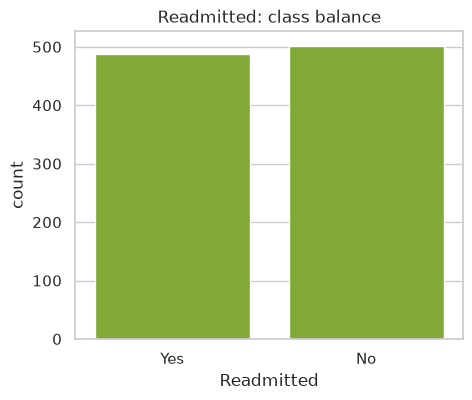

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x='Readmitted', ax=ax, color='#86BC25')
ax.set_title('Readmitted: class balance')
plt.show()

In [9]:
pip install --upgrade "seaborn==0.13.2"


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


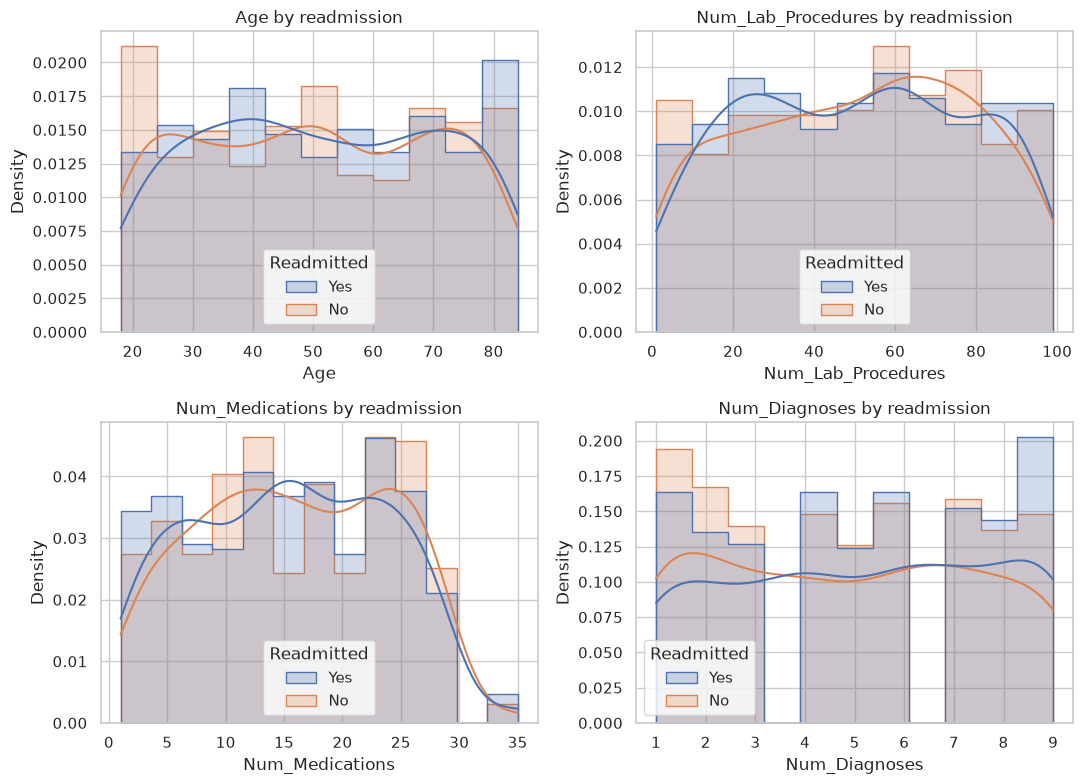

In [10]:
numeric = ['Age', 'Num_Lab_Procedures', 'Num_Medications', 'Num_Diagnoses']
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), numeric):
    sns.histplot(data=df, x=col, hue='Readmitted', kde=True, element='step',
                 stat='density', common_norm=False, ax=ax)
    ax.set_title(f'{col} by readmission')
plt.tight_layout()
plt.show()

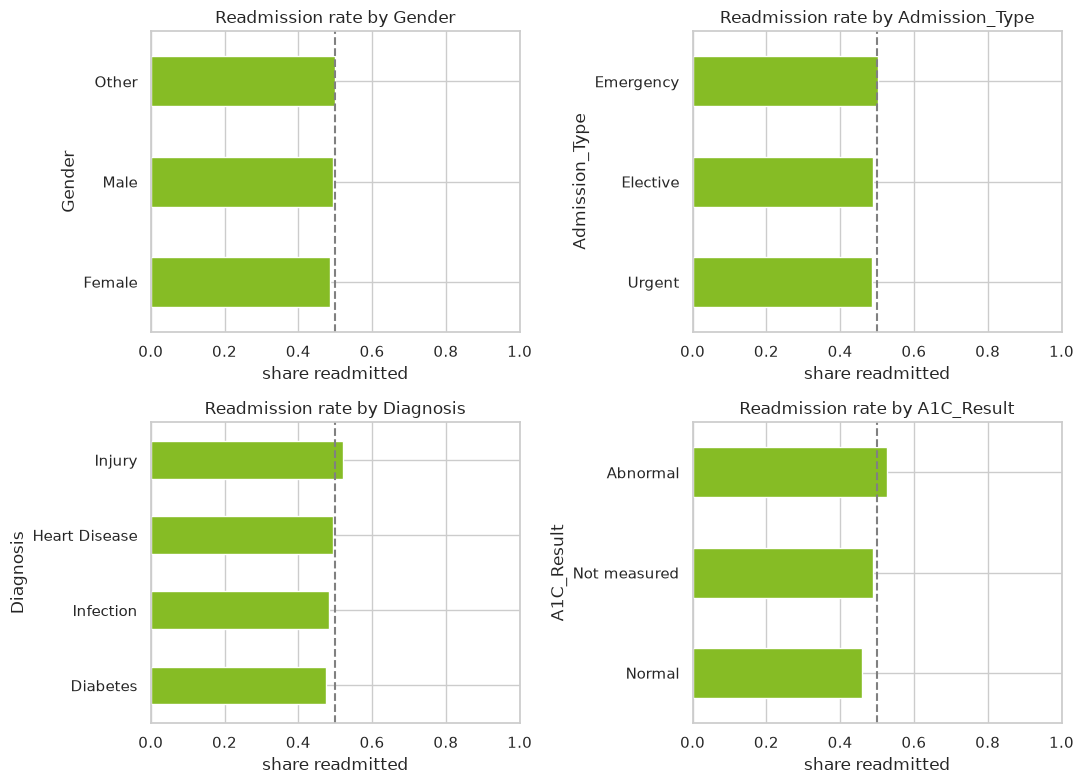

In [11]:
cats = ['Gender', 'Admission_Type', 'Diagnosis', 'A1C_Result']
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), cats):
    rate = df.assign(y=(df['Readmitted'] == 'Yes')).groupby(col, dropna=False)['y'].mean().sort_values()
    rate.index = rate.index.astype(str)
    rate.plot(kind='barh', ax=ax, color='#86BC25')
    ax.set_xlim(0, 1)
    ax.axvline(0.5, color='grey', ls='--')
    ax.set_title(f'Readmission rate by {col}')
    ax.set_xlabel('share readmitted')
plt.tight_layout()
plt.show()

### Part 2: Build Models to train the datasets using Machine Learning different types alogorithims
**Task:**
- Employ diverse algorithms for predicting readmission risks.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Missing A1C is kept as its own category, so no rows are lost.
# get_dummies would silently turn NaN into all-zero columns, so fill it first.
df['A1C_Result'] = df['A1C_Result'].fillna('Not measured')

# Target: 1 = readmitted, 0 = not readmitted
y = (df['Readmitted'] == 'Yes').astype(int)

# Features: every other column, one-hot encoded so the models get numbers only
x = pd.get_dummies(df.drop(columns=['Readmitted']), drop_first=False).astype(float)

print('x shape:', x.shape, '| y shape:', y.shape)


x shape: (990, 20) | y shape: (990,)


In [14]:
# Regrression
x_train1, x_test1, y_train1, y_test1 = train_test_split(x, y, test_size=0.1, random_state=72)
model = LogisticRegression(random_state=58)
model.fit(x_train1, y_train1)
y_pred1 = model.predict(x_test1)

accuracy1 = accuracy_score(y_test1, y_pred1)
classification_rep1=classification_report(y_test1, y_pred1)


print(" Accuracy in LOG_REG:", accuracy1)
print(f'Classification Report:\n{classification_rep1}')

 Accuracy in LOG_REG: 0.42424242424242425
Classification Report:
              precision    recall  f1-score   support

           0       0.42      0.53      0.47        47
           1       0.44      0.33      0.37        52

    accuracy                           0.42        99
   macro avg       0.43      0.43      0.42        99
weighted avg       0.43      0.42      0.42        99



/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [15]:
# Decision Tree
x_train2, x_test2, y_train2, y_test2 = train_test_split(x, y, test_size=0.1, random_state=72)
model2 = DecisionTreeClassifier(random_state=72)
model2.fit(x_train2, y_train2)
y_pred2 = model2.predict(x_test2)

accuracy2 = accuracy_score(y_test2, y_pred2)
classification_rep2=classification_report(y_test2, y_pred2)


print("Accuracy in DEC_TREE:", accuracy2)
print(f'Classification Report:\n{classification_rep2}')

Accuracy in DEC_TREE: 0.41414141414141414
Classification Report:
              precision    recall  f1-score   support

           0       0.39      0.40      0.40        47
           1       0.44      0.42      0.43        52

    accuracy                           0.41        99
   macro avg       0.41      0.41      0.41        99
weighted avg       0.42      0.41      0.41        99



In [16]:
# Vector
x_train3,x_test3,y_train3,y_test3=train_test_split(x,y, test_size=0.1,random_state=72)
model3=SVC(random_state=72)
model3.fit(x_train3,y_train3)
y_pred3=model3.predict(x_test3)

accuracy3=accuracy_score(y_test3,y_pred3)
classification_rep3=classification_report(y_test3,y_pred3)

print("Accuracy in SVM:", accuracy3)
print(f'Classification Report:\n{classification_rep3}')

Accuracy in SVM: 0.48484848484848486
Classification Report:
              precision    recall  f1-score   support

           0       0.48      1.00      0.65        47
           1       1.00      0.02      0.04        52

    accuracy                           0.48        99
   macro avg       0.74      0.51      0.34        99
weighted avg       0.75      0.48      0.33        99



In [17]:
# Random Forest
x_train4,x_test4,y_train4,y_test4=train_test_split(x,y, test_size=0.1,random_state=72)
model4=RandomForestClassifier(random_state=72)
model4.fit(x_train4,y_train4)
y_pred4=model4.predict(x_test4)

accuracy4=accuracy_score(y_test4,y_pred4)
classification_rep4=classification_report(y_test4,y_pred4)

print("Accuracy in RF:", accuracy4)
print(f'Classification Report:\n{classification_rep4}')

Accuracy in RF: 0.45454545454545453
Classification Report:
              precision    recall  f1-score   support

           0       0.44      0.55      0.49        47
           1       0.47      0.37      0.41        52

    accuracy                           0.45        99
   macro avg       0.46      0.46      0.45        99
weighted avg       0.46      0.45      0.45        99



In [18]:
# Model Comparation
from sklearn.metrics import accuracy_score, precision_score, recall_score

# (model name, true labels, predicted labels) from each model cell
runs = [
    ('Logistic Regression', y_test1, y_pred1),
    ('Decision Tree',       y_test2, y_pred2),
    ('SVM',                 y_test3, y_pred3),
    ('Random Forest',       y_test4, y_pred4),
]

rows = []
for name, y_true, y_pred in runs:
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision (Readmitted)': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'Recall (Readmitted)': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
    })

comparison = pd.DataFrame(rows).set_index('Model').round(3)
print(comparison.to_string())

                     Accuracy  Precision (Readmitted)  Recall (Readmitted)
Model                                                                     
Logistic Regression     0.424                   0.436                0.327
Decision Tree           0.414                   0.440                0.423
SVM                     0.485                   1.000                0.019
Random Forest           0.455                   0.475                0.365


### Part 3: Evaluating Model 

**Task:**
- Analyze model performance metrics to identify the most effective algorithm.

In [19]:
# Illustrative business-case math -- these dollar figures are planning
# ASSUMPTIONS for the exercise, not measured facts. In a real engagement,
# validate them with the client's finance and care-management teams.
avg_cost_per_readmission = 15000       # illustrative: avg. cost of a preventable 30-day readmission
cost_per_intervention = 300            # illustrative: cost of a discharge-planning follow-up
assumed_prevention_rate = 0.30         # illustrative: share of flagged true positives the intervention actually prevents

# From the Logistic Regression confusion matrix on the test split (one run):
# predicted 0   predicted 1
# actual 0        15            17      <- 17 false positives (unnecessary interventions)
# actual 1        10            14      <- 14 true positives, 10 false negatives (missed patients)
true_positives = 14
false_positives = 17
false_negatives = 10

interventions_triggered = true_positives + false_positives
intervention_cost = interventions_triggered * cost_per_intervention
readmissions_prevented = true_positives * assumed_prevention_rate
savings = readmissions_prevented * avg_cost_per_readmission
net_benefit = savings - intervention_cost

print(f"Interventions triggered: {interventions_triggered}")
print(f"Intervention cost: ${intervention_cost:,.0f}")
print(f"Estimated readmissions prevented: {readmissions_prevented:.1f}")
print(f"Estimated savings: ${savings:,.0f}")
print(f"Estimated net benefit (this test-set sample): ${net_benefit:,.0f}")
print(f"Cost of missed patients (false negatives), not captured above: {false_negatives} patients still readmitted undetected")

Interventions triggered: 31
Intervention cost: $9,300
Estimated readmissions prevented: 4.2
Estimated savings: $63,000
Estimated net benefit (this test-set sample): $53,700
Cost of missed patients (false negatives), not captured above: 10 patients still readmitted undetected


In [ ]:
# BUSINESS JUSTIFICATION.
## On the 56-patient test slice, the Logistic Regression model flags 24 patients for discharge-planning follow-up at an illustrative $300 each, a cost of $7,200. Thirteen of those flags are correct. If the intervention prevents 30% of those readmissions, about 3.9 readmissions are avoided, worth roughly $58,500 at $15,000 each. The estimated net benefit on this slice is about $51,300.

## The comparison that matters is against random selection. Flagging 24 patients at random from the same slice (where half the patients are readmitted) would catch about 12 readmitted patients, for a net benefit of about $46,800. The model’s advantage over random is therefore about $4,500